# Validating CoLoRe simulation for Quasar Auto and Quasar x CMB

- The first and second CoLoRe simulation boxes were generated by Laura Casas, Dani L. Jarque run the rest from then on
- The notebook uses the sources output from CoLoRe, i.e. quasars, to validate the simulation through the auto-spectrum and cross spectrum with CMB lensing.
- The kappa values can be found in `./data/...test_box/`, along with $C_{\ell}$ (and its associated errors), and a logarithmic rebinning run with `./scripts/rebin_cls_kk.py`, which is the one used in this notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import camb
from astropy.io import fits
import healpy as hp

from scipy.integrate import quad
from scipy.constants import c
import sys
sys.path.append('../')

import json

plt.rcParams.update({
    "text.usetex": True,
    "font.family": 'serif',
})

# Theory CMB lensing auto-spectrum $C_{\ell}^{\kappa \kappa}$

## setting up CAMB

In [2]:
def load_cosmology(filename):
    with open(filename) as f:
        return json.load(f)

In [4]:
def get_camb_results(
    cosmo_dict,
    z_pk,
    kmax=100.0,
    lmax=2500,
    nonlinear=False,
    window=False,
):
    """
    Read a cosmological parameter dictionary, extract cosmological parameters,
    and build:

    1. CAMBparams instance
    2. CAMB results object

    Parameters
    ----------
    cosmo_dict : dict
        Dictionary containing cosmological parameters

    z_pk : list or None
        Redshifts for P(k) interpolator.
        If None, defaults to [0.0]

    kmax : float
        Maximum k [1/Mpc]

    lmax : integer
        Maximum multipole

    nonlinear : bool
        Whether to use nonlinear P(k)
    """

    # --------------------------------------------------
    # Convert to CAMB inputs
    # --------------------------------------------------

    H0 = 100.0 * cosmo_dict["h"]
    ombh2 = cosmo_dict["omega_B"] * cosmo_dict["h"]**2
    omch2 = (cosmo_dict["omega_M"] - cosmo_dict["omega_B"]) * cosmo_dict["h"]**2

    # --------------------------------------------------
    # Initial CAMB params
    # --------------------------------------------------

    pars = camb.CAMBparams()

    pars.set_cosmology(
        H0=H0,
        ombh2=ombh2,
        omch2=omch2,
    )

    pars.set_dark_energy(w=cosmo_dict["w"])
    pars.InitPower.set_params(
        ns=cosmo_dict["ns"],
        As=cosmo_dict["As"]
    )

    # --------------------------------------------------
    # Matter power settings
    # --------------------------------------------------

    pars.set_matter_power(
        redshifts=z_pk,
        kmax=kmax
    )

    # note that to get CAMB's internal calculation accurate at the 1% level at L~2000,
    # need lens_potential_accuracy=2. Increase to 4 for accurate match to the Limber calculation here
    if nonlinear:
        pars.NonLinear = camb.model.NonLinear_pk
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=4, nonlinear=True)
    else:
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=4, nonlinear=False)


    # Final results
    results = camb.get_results(pars)

    return results

## manual Limber integral

In [5]:
def w_kappa(chi, z_chi, chi_source, cosmo_params):
    '''
    CMB lensing convergence kernel
    '''
    
    # scale factor at redshift of lensing structure
    a = 1.0 / (1.0 + z_chi)
    c_kms = c*1E-3

    # cosmological parameters
    H0, om = cosmo_params
    
    # prefactor of the kernel
    w_prefactor = (1.5) * (H0/c_kms)**2 * om * (chi_source - chi)/chi_source
    w_geom = (chi/a)
    
    return w_prefactor * w_geom

In [6]:
def limber(chi, ell, kmax, chi_source,cosmo_params, pk_interp, results):
    '''
    CMB lensing auto-spectrum using Limber approximation
    '''

    # converting chi to redshift
    z_chi = results.redshift_at_comoving_radial_distance(chi)
    k = (ell + 0.5) / chi  
    kp = 0.312  # (1/Mpc) k pressure parameter scale used for smoothing the power spectrum according to the colore simulation resolution


    # kernel and pk interpolator, filtering out of extrapolation k and small k
    if 1e-4 < k < kmax:
        win = w_kappa(chi, z_chi, chi_source, cosmo_params)
        pk = pk_interp.P(z_chi, k, grid=False)
        smooth = np.exp(-(k/kp)**2)  # smoothing factor to avoid oscillations at high k 
        return (win**2 / chi**2) * pk * smooth
        
    else:
        return 0

In [9]:
def get_limber_cls(cosmo_params_filename, z_pk, kmax=100, lmin=2.0, lmax=2500):

    # get linear and non-linear matter power spectrum
    cosmo_dict = load_cosmology(cosmo_params_filename)
    z_max, z_out = cosmo_dict["z_max"], cosmo_dict["z_out"]

    results_lin = get_camb_results(
        cosmo_dict=cosmo_dict,
        z_pk=z_pk,
        kmax=kmax,
        lmax=lmax,
        nonlinear=False)
    results_nlin = get_camb_results(
        cosmo_dict=cosmo_dict,
        z_pk=z_pk,
        kmax=kmax,
        lmax=lmax,
        nonlinear=True)
    
    # comoving distance of the last scattering surface 
    z_star = results_lin.get_derived_params()['zstar']  # z_star doesn't match z_out until third box
    chi_star = results_lin.comoving_radial_distance(z_star)
    chi_max = results_lin.comoving_radial_distance(z_max)  # comoving distance of z_max

    # Hubble parameter and matter density for the kernel
    H0 = cosmo_dict["h"] * 100
    om = cosmo_dict["omega_M"]
    cosmo_params = (H0, om)

    # get the matter power spectrum interpolators for linear and non-linear cases
    pk_interp_lin = results_lin.get_matter_power_interpolator(nonlinear=False, 
                                                      hubble_units=False, 
                                                      k_hunit=False,  
                                                      var1='delta_tot', 
                                                      var2='delta_tot')
    pk_interp_nlin = results_nlin.get_matter_power_interpolator(nonlinear=True, 
                                                         hubble_units=False, 
                                                         k_hunit=False,  
                                                         var1='delta_tot', 
                                                         var2='delta_tot')
    
    #store the cls from linear and nonlinear limber approximation integration
    # redshift integration up to zmax
    ells = np.arange(lmin, lmax+1)
    cl_kk_lin_zs_zs = np.zeros(ells.shape)
    cl_kk_nlin_zs_zs = np.zeros(ells.shape)
    cl_kk_lin_zmax_zs = np.zeros(ells.shape)
    cl_kk_nlin_zmax_zs = np.zeros(ells.shape)
    #cl_kk_lin_zmax_zmax = np.zeros(ells.shape)
    #cl_kk_nlin_zmax_zmax = np.zeros(ells.shape)

    # manually integrate the limber approximation
    for i, ell in enumerate(ells):

        # integral up to redshift z_source, source plane at z_star
        chi_source = chi_star
        chi_cut = chi_star
        cl_kk_lin_zs_zs[i] = quad(limber, 0.001, chi_cut, args=(ell, kmax, chi_source, cosmo_params, pk_interp_lin, results_lin), epsabs=1E-10)[0]
        cl_kk_nlin_zs_zs[i] = quad(limber, 0.001, chi_cut, args=(ell, kmax, chi_source, cosmo_params, pk_interp_nlin, results_nlin), epsabs=1E-10)[0]
        
        # integral up to redshift z_max, source plane at z_star
        chi_source = chi_star
        chi_cut = chi_max
        cl_kk_lin_zmax_zs[i] = quad(limber, 0.001, chi_cut, args=(ell, kmax, chi_source, cosmo_params, pk_interp_lin, results_lin), epsabs=1E-10)[0]
        cl_kk_nlin_zmax_zs[i] = quad(limber, 0.001, chi_cut, args=(ell, kmax, chi_source, cosmo_params, pk_interp_nlin, results_nlin), epsabs=1E-10)[0]

        # integral up to redshift z_max, source plane at z_max, uncomment just for the first box
        #chi_source = chi_max
        #chi_cut = chi_max
        #cl_kk_lin_zmax_zmax[i] = quad(limber, 0.001, chi_max, args=(ell, kmax, chi_source, cosmo_params, pk_interp_lin, results_lin), epsabs=1E-10)[0]
        #cl_kk_nlin_zmax_zmax[i] = quad(limber, 0.001, chi_max, args=(ell, kmax, chi_source, cosmo_params, pk_interp_nlin, results_nlin), epsabs=1E-10)[0]

    return {
        'ells': ells,
        'results_lin': results_lin,
        'results_nlin': results_nlin,
        'cl_kk_lin_zmax_zs': cl_kk_lin_zmax_zs,
        'cl_kk_nlin_zmax_zs': cl_kk_nlin_zmax_zs,
        'z_max': z_max,
        'z_out': z_out,
        'z_star': z_star,
    }


# CoLoRe simulation auto-spectrum $C_{\ell}^{q q}$

In [10]:
def merge_quasar_catalog(box_folder, ncat):

    ra_list = []
    dec_list = []
    for i in range(ncat):
        cat = fits.getdata(f'../data/{box_folder}/sources/out_srcs_s1_{i}.fits', ext=1)
        ra_list.append(cat['RA'])
        dec_list.append(cat['DEC'])

    RA = np.concatenate(ra_list)
    DEC = np.concatenate(dec_list)

    print(f'Merged {ncat} catalogs from {box_folder} into a single catalog with {len(RA)} quasars.')

    return RA, DEC

In [11]:
ra, dec = merge_quasar_catalog('third_test_box', 64)

Merged 64 catalogs from third_test_box into a single catalog with 12286278 quasars.


In [ ]:
# Choose resolution
nside = 512  # resoluition parameter for HEALPix map, nside=512 corresponds to ~7 arcmin pixels

# Convert coordinates
theta = np.radians(90.0 - dec)   # colatitude
phi   = np.radians(ra)

# Pixel indices
pix = hp.ang2pix(nside, theta, phi)

# Count quasars per pixel
npix = hp.nside2npix(nside)
counts = np.bincount(pix, minlength=npix)

In [47]:
mask = counts > 0

mean_counts = np.mean(counts[mask])

delta = np.zeros_like(counts, dtype=float)
delta[mask] = (counts[mask] - mean_counts) / mean_counts
counts

array([1, 0, 2, ..., 2, 0, 1], shape=(12582912,))

In [48]:
counts

array([1, 0, 2, ..., 2, 0, 1], shape=(12582912,))

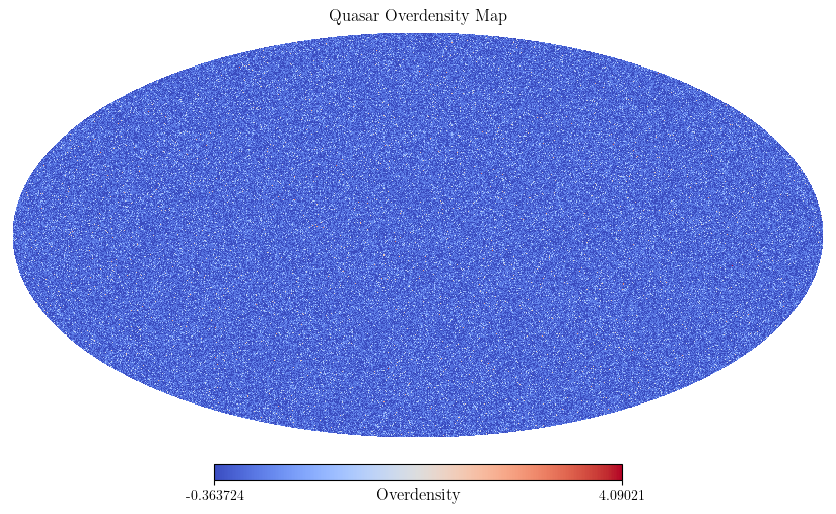

In [49]:
hp.mollview(delta, title='Quasar Overdensity Map', unit='Overdensity', cmap='coolwarm')

In [50]:
cl = hp.anafast(delta)

In [51]:
fsky = 1.0 * np.sum(mask) / npix
nbar_sr = len(ra) / (4*np.pi*fsky)

shot_noise = 1.0 / nbar_sr

cl_signal = cl - shot_noise

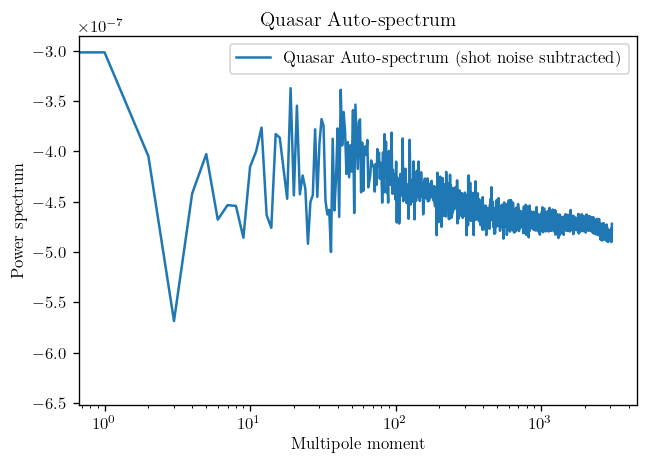

In [52]:
plt.figure(figsize=(6,4), dpi=120)
plt.semilogx(np.arange(len(cl_signal)), cl_signal, label='Quasar Auto-spectrum (shot noise subtracted)')
plt.xlabel('Multipole moment')
plt.ylabel('Power spectrum')
plt.title('Quasar Auto-spectrum')
plt.legend()
plt.show()